# Level 2 - Task 1: Logistic Regression for Binary Classification
**Codveda ML Internship**

**Dataset:** Telco Customer Churn. Goal: predict whether a customer will **churn** (leave) or stay.

**Steps:** 1) Load & preprocess  2) Train logistic regression  3) Interpret coefficients & odds ratios  4) Evaluate (accuracy, precision, recall, ROC curve)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, classification_report)

## 1. Load the dataset

In [2]:
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df = pd.read_csv(url)
print('Shape:', df.shape)
print(df['Churn'].value_counts())
df.head()

Shape: (7043, 21)
Churn
No     5174
Yes    1869
Name: count, dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Preprocessing
- Drop `customerID` (just an identifier)
- `TotalCharges` is stored as text and has blank values -> convert to number, fill blanks with median
- Target `Churn`: Yes = 1, No = 0
- Categorical columns -> one-hot encoding
- Numeric columns -> standardization (after the split)

In [3]:
df = df.drop(columns=['customerID'])

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing TotalCharges:', df['TotalCharges'].isna().sum())
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

df = pd.get_dummies(df, drop_first=True, dtype=int)
print('Shape after encoding:', df.shape)
df.head()

Missing TotalCharges: 11
Shape after encoding: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [4]:
X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (5634, 30) | Test: (1409, 30)


## 3. Train the logistic regression model

In [5]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print('Model trained. Test accuracy:', round(accuracy_score(y_test, y_pred), 4))

Model trained. Test accuracy: 0.8055


## 4. Interpret coefficients and odds ratios
- **Coefficient**: change in the log-odds of churn for a 1-unit increase in the feature.
- **Odds ratio = exp(coefficient)**:
  - > 1 -> feature **increases** the odds of churn
  - < 1 -> feature **decreases** the odds of churn
  - Numeric features are standardized, so their odds ratio is per 1 standard deviation.

In [6]:
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0],
    'Odds Ratio': np.exp(model.coef_[0])
}).sort_values('Coefficient', ascending=False)

print('Top 8 features that INCREASE churn:')
display(coef_df.head(8).round(3))
print('Top 8 features that DECREASE churn:')
display(coef_df.tail(8).round(3))

Top 8 features that INCREASE churn:


,Feature,Coefficient,Odds Ratio
10,InternetService_Fiber optic,1.191,3.289
3,TotalCharges,0.511,1.668
23,StreamingMovies_Yes,0.380,1.463
21,StreamingTV_Yes,0.379,1.461
28,PaymentMethod_Electronic check,0.378,1.459
26,PaperlessBilling_Yes,0.372,1.450
9,MultipleLines_Yes,0.365,1.441
0,SeniorCitizen,0.145,1.156


Top 8 features that DECREASE churn:


,Feature,Coefficient,Odds Ratio
8,MultipleLines_No phone service,-0.247,0.781
19,TechSupport_Yes,-0.298,0.742
13,OnlineSecurity_Yes,-0.348,0.706
2,MonthlyCharges,-0.478,0.620
7,PhoneService_Yes,-0.491,0.612
24,Contract_One year,-0.691,0.501
1,tenure,-1.238,0.290
25,Contract_Two year,-1.337,0.263


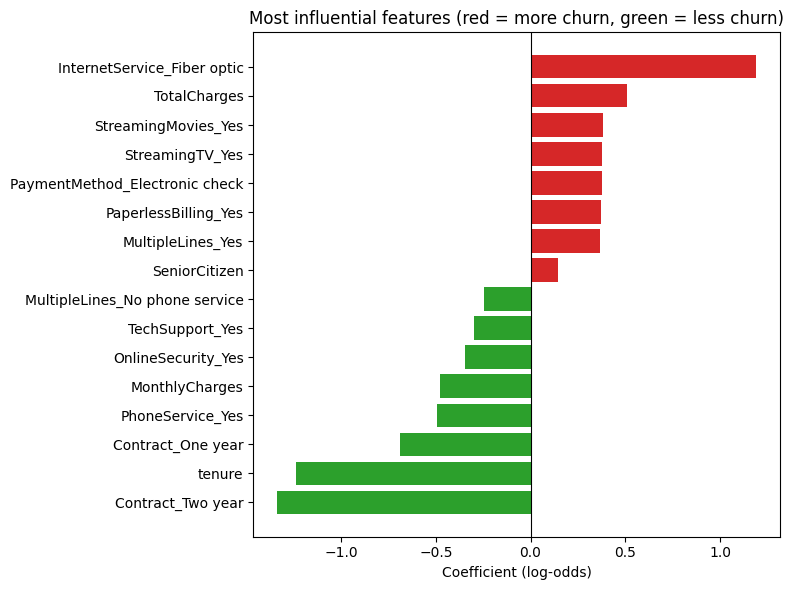

In [7]:
top = pd.concat([coef_df.head(8), coef_df.tail(8)]).sort_values('Coefficient')
colors = ['tab:red' if c > 0 else 'tab:green' for c in top['Coefficient']]
plt.figure(figsize=(8, 6))
plt.barh(top['Feature'], top['Coefficient'], color=colors)
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Coefficient (log-odds)')
plt.title('Most influential features (red = more churn, green = less churn)')
plt.tight_layout()
plt.show()

## 5. Evaluation: accuracy, precision, recall, confusion matrix

Accuracy :

 0.8055
Precision: 0.6572
Recall   : 0.5588

              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



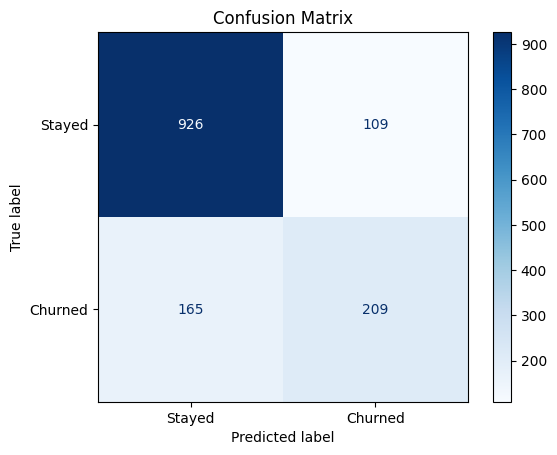

In [8]:
print('Accuracy :', round(accuracy_score(y_test, y_pred), 4))
print('Precision:', round(precision_score(y_test, y_pred), 4))
print('Recall   :', round(recall_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=['Stayed', 'Churned']))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['Stayed', 'Churned']).plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

## 6. ROC curve and AUC

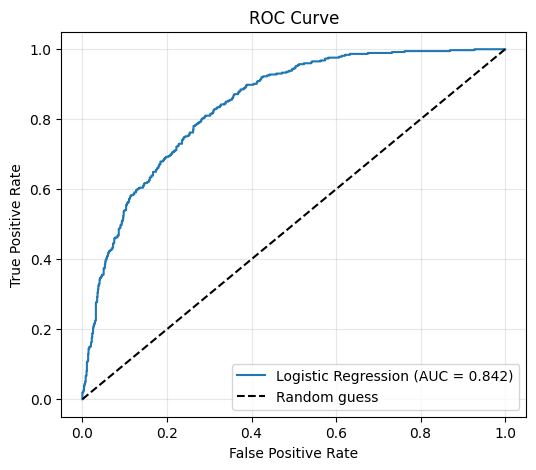

In [9]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Summary
- Logistic regression predicts churn with about 80% accuracy and a good AUC (~0.84).
- **Recall for churners is lower than for loyal customers** because the data is imbalanced (about 27% churn).
- Odds ratios show what drives churn: month-to-month contracts, fiber optic internet and electronic check payments raise churn odds, while longer tenure and longer contracts reduce it.
- Business use: target high-risk customers with retention offers (e.g. discounts for longer contracts).